# Laboratorio 4

Integrantes:

- Nicolas Mario Romero Colmenares - 202321309

## 0. Importacion de librerias

In [22]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

TAMANO = (128, 128)

## 1. Pipeline de preparación y representación 

### 1.1 Transformaciones del pipeline

In [15]:
class ImagenAPixeles(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        img = np.asarray(X)
        if img.ndim != 3 or img.shape[2] != 3:
            raise ValueError("Se espera una imagen RGB de forma (H, W, 3).")

        img = img.astype(np.float64)
        if img.max() > 1.0:
            img = img / 255.0

        h, w, _ = img.shape
        # Coordenadas normalizadas a [0, 1]
        xs = np.linspace(0, 1, w)
        ys = np.linspace(0, 1, h)
        xx, yy = np.meshgrid(xs, ys)

        color = img.reshape(-1, 3)
        pos = np.column_stack([xx.ravel(), yy.ravel()])
        return np.hstack([color, pos])  # (H*W, 5)

class PonderadorCaracteristicas(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=1.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        pesos = np.array([self.beta] * 3 + [self.lam] * 2, dtype=np.float64)
        return X * pesos


def construir_pipeline(beta=1.0, lam=1.0):
    return Pipeline([
        ("pixeles", ImagenAPixeles()),
        ("pesos", PonderadorCaracteristicas(beta=beta, lam=lam)),
    ])

### 1.2 Carga de imágenes y preparación de máscaras

In [16]:
ruta_imagenes = "./ISBI2016_ISIC_Part1_Training_Data"
ruta_mascaras = "./ISBI2016_ISIC_Part1_Training_GroundTruth"

def cargar_imagen(ruta, tamano=TAMANO):
    img = Image.open(ruta).convert("RGB")
    img = img.resize(tamano, Image.BILINEAR)
    return np.asarray(img)  # uint8 (H, W, 3)


def cargar_mascara(ruta, tamano=TAMANO):
    m = Image.open(ruta).convert("L")
    m = m.resize(tamano, Image.NEAREST)
    m = np.asarray(m)
    return (m > 127).astype(np.uint8)


def cargar_dataset(ruta_img, ruta_mask, tamano=TAMANO):
    rutas = sorted(glob.glob(os.path.join(ruta_img, "*.jpg")))
    imagenes, mascaras, nombres = [], [], []
    for r in rutas:
        base = os.path.splitext(os.path.basename(r))[0]
        r_mask = os.path.join(ruta_mask, f"{base}_Segmentation.png")
        if not os.path.exists(r_mask):
            print(f"Advertencia: sin máscara para {base}, se omite.")
            continue
        imagenes.append(cargar_imagen(r, tamano))
        mascaras.append(cargar_mascara(r_mask, tamano))
        nombres.append(base)
    return imagenes, mascaras, nombres


imagenes, mascaras, nombres = cargar_dataset(ruta_imagenes, ruta_mascaras)
print(f"Imágenes cargadas: {len(imagenes)}")
assert len(imagenes) == 20, "Se esperaban 20 imágenes."

Imágenes cargadas: 20


### 1.3 División en conjuntos de ajuste y prueba

In [17]:
N_AJUSTE = 15

imgs_ajuste, masks_ajuste, nombres_ajuste = (
    imagenes[:N_AJUSTE], mascaras[:N_AJUSTE], nombres[:N_AJUSTE])
imgs_prueba, masks_prueba, nombres_prueba = (
    imagenes[N_AJUSTE:], mascaras[N_AJUSTE:], nombres[N_AJUSTE:])

print(f"Ajuste: {len(imgs_ajuste)} imágenes | Prueba: {len(imgs_prueba)} imágenes")

Ajuste: 15 imágenes | Prueba: 5 imágenes


### 1.4 Verificación del pipeline y de las máscaras

In [18]:
# Comprobacion de formas y rangos
pipe = construir_pipeline(beta=1.0, lam=1.0)
X = pipe.fit_transform(imgs_ajuste[0])
print("Forma de X:", X.shape, "(esperado:", (TAMANO[0] * TAMANO[1], 5), ")")
print("Mín/Máx por columna:\n", X.min(axis=0), "\n", X.max(axis=0))

# Comprobacion de que β y λ se modifican sin cambiar la implementación
pipe.set_params(pesos__beta=0.0, pesos__lam=1.0)   # solo posición
X_pos = pipe.fit_transform(imgs_ajuste[0])
print("\nβ=0, λ=1 -> columnas de color nulas:", np.allclose(X_pos[:, :3], 0))

pipe.set_params(pesos__beta=1.0, pesos__lam=0.0)   # solo color
X_col = pipe.fit_transform(imgs_ajuste[0])
print("β=1, λ=0 -> columnas de posición nulas:", np.allclose(X_col[:, 3:], 0))

# Comprobacion de las mascaras
for m in masks_ajuste + masks_prueba:
    assert set(np.unique(m)).issubset({0, 1})
print("\nTodas las máscaras son binarias {0, 1}.")
print("Fracción de lesión por imagen (ajuste):",
      np.round([m.mean() for m in masks_ajuste], 2))

Forma de X: (16384, 5) (esperado: (16384, 5) )
Mín/Máx por columna:
 [0.24705882 0.04705882 0.00784314 0.         0.        ] 
 [0.83921569 0.71372549 0.70588235 1.         1.        ]

β=0, λ=1 -> columnas de color nulas: True
β=1, λ=0 -> columnas de posición nulas: True

Todas las máscaras son binarias {0, 1}.
Fracción de lesión por imagen (ajuste): [0.13 0.23 0.38 0.12 0.06 0.07 0.19 0.11 0.2  0.03 0.36 0.39 0.19 0.15
 0.14]


### 1.5 Visualización de ejemplos

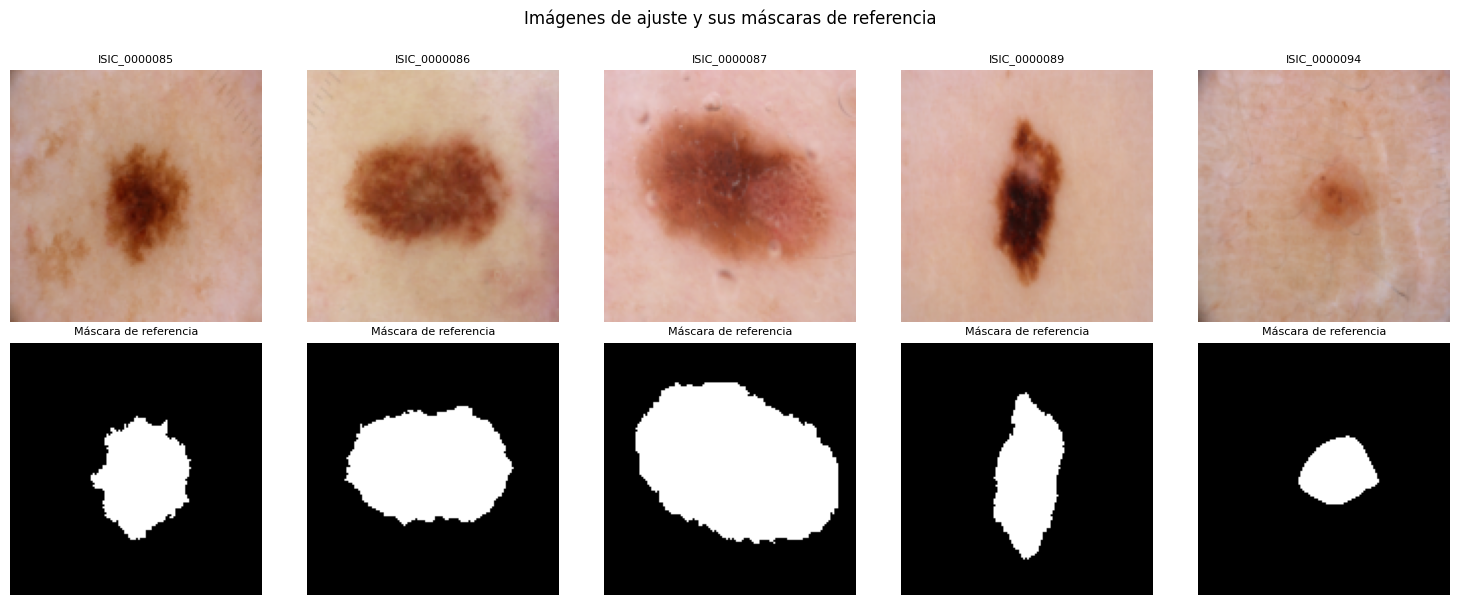

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    axes[0, i].imshow(imgs_ajuste[i])
    axes[0, i].set_title(nombres_ajuste[i], fontsize=8)
    axes[1, i].imshow(masks_ajuste[i], cmap="gray")
    axes[1, i].set_title("Máscara de referencia", fontsize=8)
    for ax in axes[:, i]:
        ax.axis("off")
plt.suptitle("Imágenes de ajuste y sus máscaras de referencia", y=1.0)
plt.tight_layout()
plt.show()

## 2. Agrupación y selección de K

### 2.1 Configuración de la exploración

In [20]:
#Parametros reproducibles
SEMILLA = 42
TAM_MUESTRA = 2000
N_INIT = 5
K_RANGO = range(2, 9)

COMBINACIONES = [
    {"nombre": "solo color",     "beta": 1.0, "lam": 0.0},    # λ/β = 0
    {"nombre": "λ/β = 0.1",      "beta": 1.0, "lam": 0.1},
    {"nombre": "λ/β = 0.25",     "beta": 1.0, "lam": 0.25},
    {"nombre": "λ/β = 0.5",      "beta": 1.0, "lam": 0.5},
    {"nombre": "λ/β = 1",        "beta": 1.0, "lam": 1.0},
    {"nombre": "λ/β = 1.5",      "beta": 1.0, "lam": 1.5},
    {"nombre": "λ/β = 2",        "beta": 1.0, "lam": 2.0},
    {"nombre": "λ/β = 3",        "beta": 1.0, "lam": 3.0},
    {"nombre": "λ/β = 5",        "beta": 1.0, "lam": 5.0},
    {"nombre": "solo posición",  "beta": 0.0, "lam": 1.0},    # λ/β = ∞
]
assert len(COMBINACIONES) == 10

n_pix = TAMANO[0] * TAMANO[1]

rng = np.random.default_rng(SEMILLA)
IDX_MUESTRA = np.sort(rng.choice(n_pix, size=TAM_MUESTRA, replace=False))

print(f"Semilla: {SEMILLA} | Muestra de silueta: {TAM_MUESTRA} de {n_pix} píxeles "
      f"({TAM_MUESTRA / n_pix:.1%}) | n_init: {N_INIT} | K ∈ {list(K_RANGO)}")

Semilla: 42 | Muestra de silueta: 2000 de 16384 píxeles (12.2%) | n_init: 5 | K ∈ [2, 3, 4, 5, 6, 7, 8]


### 2.2 Agrupación y selección de K por silueta

In [21]:
def agrupar_imagen(img, beta, lam, k_rango=K_RANGO):
    pipe = construir_pipeline()
    pipe.set_params(pesos__beta=beta, pesos__lam=lam)
    X = pipe.fit_transform(img)
    X_muestra = X[IDX_MUESTRA]

    siluetas, etiquetas = {}, {}
    for k in k_rango:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEMILLA).fit(X)
        etq = km.labels_
        etiquetas[k] = etq.astype(np.int8)
        etq_m = etq[IDX_MUESTRA]
        if len(np.unique(etq_m)) < 2:
            siluetas[k] = np.nan
        else:
            siluetas[k] = silhouette_score(X_muestra, etq_m)

    k_opt = max((k for k in siluetas if not np.isnan(siluetas[k])),
                key=lambda k: siluetas[k])
    return {"siluetas": siluetas, "k_opt": k_opt, "etiquetas": etiquetas}

resultados = {}
for i, img in enumerate(imgs_ajuste):
    for j, c in enumerate(COMBINACIONES):
        resultados[(i, j)] = agrupar_imagen(img, c["beta"], c["lam"])
    print(f"Imagen {i + 1}/{len(imgs_ajuste)} ({nombres_ajuste[i]}) lista")

Imagen 1/15 (ISIC_0000085) lista
Imagen 2/15 (ISIC_0000086) lista
Imagen 3/15 (ISIC_0000087) lista
Imagen 4/15 (ISIC_0000089) lista
Imagen 5/15 (ISIC_0000094) lista
Imagen 6/15 (ISIC_0000105) lista
Imagen 7/15 (ISIC_0000108) lista
Imagen 8/15 (ISIC_0000110) lista
Imagen 9/15 (ISIC_0000112) lista
Imagen 10/15 (ISIC_0000114) lista
Imagen 11/15 (ISIC_0000116) lista
Imagen 12/15 (ISIC_0000122) lista
Imagen 13/15 (ISIC_0000123) lista
Imagen 14/15 (ISIC_0000128) lista
Imagen 15/15 (ISIC_0000133) lista


### 2.3 Resumen de la selección de K

,solo color,λ/β = 0.1,λ/β = 0.25,λ/β = 0.5,λ/β = 1,λ/β = 1.5,λ/β = 2,λ/β = 3,λ/β = 5,solo posición
ISIC_0000085,2,2,2,2,5,5,5,5,5,4
ISIC_0000086,2,2,2,2,5,5,5,5,5,4
ISIC_0000087,2,2,2,2,5,5,5,5,5,4
ISIC_0000089,2,2,2,2,5,5,5,5,5,4
ISIC_0000094,2,2,5,5,5,5,5,4,4,4
ISIC_0000105,2,2,2,6,5,5,5,5,4,4
ISIC_0000108,2,2,2,2,5,5,5,5,5,4
ISIC_0000110,2,2,2,6,6,5,5,4,4,4
ISIC_0000112,2,2,2,5,5,5,5,5,4,4
ISIC_0000114,2,2,2,5,5,4,4,4,4,4


,2,3,4,5,6,7,8
solo color,0.757,0.591,0.486,0.456,0.427,0.412,0.404
λ/β = 0.1,0.724,0.515,0.412,0.379,0.354,0.352,0.353
λ/β = 0.25,0.620,0.385,0.383,0.383,0.390,0.388,0.372
λ/β = 0.5,0.446,0.381,0.402,0.418,0.409,0.388,0.369
λ/β = 1,0.319,0.362,0.400,0.433,0.405,0.383,0.371
λ/β = 1.5,0.327,0.346,0.379,0.428,0.398,0.381,0.374
λ/β = 2,0.332,0.352,0.375,0.419,0.393,0.377,0.376
λ/β = 3,0.342,0.361,0.382,0.405,0.386,0.373,0.374
λ/β = 5,0.347,0.367,0.389,0.391,0.379,0.372,0.368
solo posición,0.355,0.370,0.395,0.374,0.378,0.375,0.366


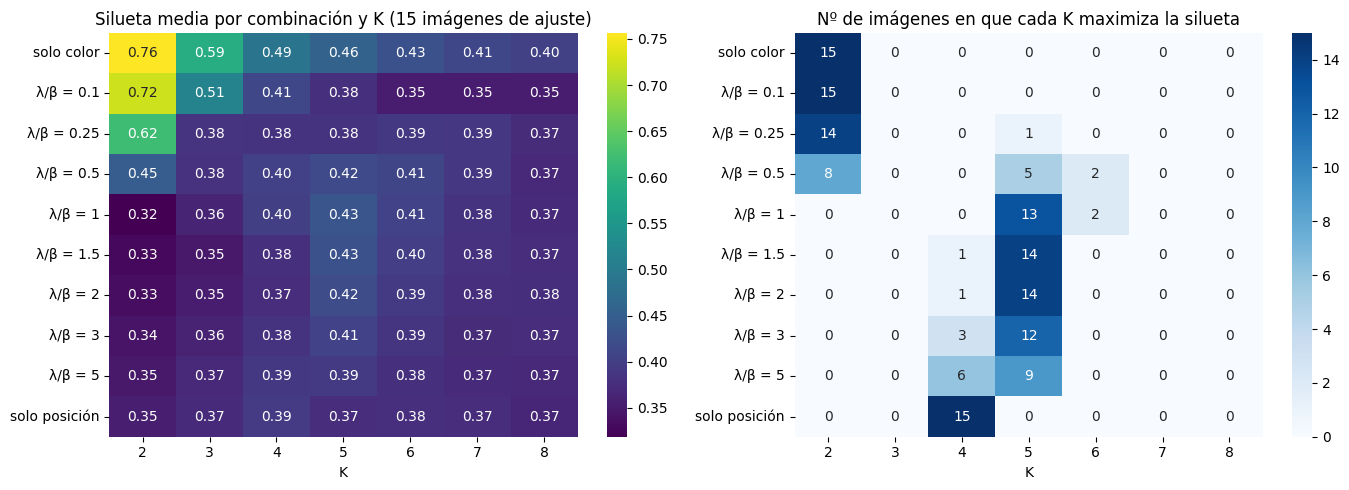

In [23]:
nombres_comb = [c["nombre"] for c in COMBINACIONES]
n_img = len(imgs_ajuste)

# Tabla de K elegido: filas = imagenes, columnas = combinaciones
tabla_k = pd.DataFrame(
    [[resultados[(i, j)]["k_opt"] for j in range(10)] for i in range(n_img)],
    index=nombres_ajuste, columns=nombres_comb)
display(tabla_k)

# Silueta media (sobre las imagenes de ajuste) para cada combinación y K
sil_media = pd.DataFrame(
    [[np.nanmean([resultados[(i, j)]["siluetas"][k] for i in range(n_img)])
      for k in K_RANGO] for j in range(10)],
    index=nombres_comb, columns=list(K_RANGO))
display(sil_media.round(3))

# Frecuencia de cada K elegido por combinacion
frec_k = pd.DataFrame(
    [[(tabla_k.iloc[:, j] == k).sum() for k in K_RANGO] for j in range(10)],
    index=nombres_comb, columns=list(K_RANGO))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(sil_media, annot=True, fmt=".2f", cmap="viridis", ax=axes[0])
axes[0].set_title("Silueta media por combinación y K (15 imágenes de ajuste)")
axes[0].set_xlabel("K"); axes[0].set_ylabel("")

sns.heatmap(frec_k, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Nº de imágenes en que cada K maximiza la silueta")
axes[1].set_xlabel("K"); axes[1].set_ylabel("")

plt.tight_layout()
plt.show()